# SNOOPPI: executed experiment record

**15 completed classifier fits · seed 44 · 17,033 retained pairs.**

This notebook was assembled **after** the original command-line training run. Its executed cells load and verify the saved aggregate records and draw the learning curves; they do not rerun clustering or training. Every displayed epoch comes from the original saved history CSVs. See `02_training_code_and_rerun.ipynb` for the complete training source and an optional rerun cell.

Best observed test macro-AP: ProtT5 + RF **0.6168**. Among full MLPs, ESM-C scores **0.5996**. One seed, substantial pair exclusions, test dependence, and legacy cache provenance limit interpretation. No significance claim is made.

## Setup and provenance
Run from this folder in a repository clone with pandas, matplotlib and Jupyter installed. Only public aggregate files are read. Original scientific run: 30 October 2026; source commit `81f2dcc0353ada133fec0f1dac5e8a327ce4f5a4`.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results/training_manifest.json").exists())
RESULTS = ROOT / "results"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
metrics = pd.read_csv(RESULTS / "metrics.csv")
manifest = json.loads((RESULTS / "training_manifest.json").read_text())
assert hashlib.sha256((ROOT / "train.py").read_bytes()).hexdigest() == manifest["script_sha256"]
assert len(metrics) == 45
print("Loaded 15 completed fits; training source matches the recorded hash.")

Loaded 15 completed fits; training source matches the recorded hash.


In [2]:
display(pd.json_normalize(manifest).T.rename(columns={0:"Recorded value"}))

,Recorded value
seed,44
split_manifest_sha256,7cffb03bdaa1c669ccc8df2d007d0114772d964bcdb136...
torch,2.15.0+cpu
numpy,2.3.5
pandas,2.2.3
sklearn,1.8.0
python,"3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 2..."
script_sha256,2b95839449f6727e6f51c5121402bddb5062028d039f28...
caches.prott5.sha256,93a72e4aaa6b6f0d9a3cbc4023453bd2747c62e4fe08fc...
caches.prott5.metadata.format,legacy_direct_dictionary


## Audit, clustering, and frozen partitions
30% sequence identity, 80% bidirectional coverage, full-length sequences. A giant interaction component required excluding cross-partition edges. All encoders used the same frozen partitions.

In [3]:
audit = json.loads((RESULTS / "audit.json").read_text())
display(pd.Series({k:v for k,v in audit.items() if not isinstance(v, dict)}, name="Pairs / sequences").to_frame())
feasibility = json.loads((RESULTS / "feasibility.json").read_text())
display(pd.DataFrame(feasibility["splits"]).T)
display(pd.read_csv(RESULTS / "input_overlap.csv"))

,Pairs / sequences
source_rows,39003
invalid_rows,588
conflict_rows,1086
duplicate_rows,0
normalized_collision_rows,350
retained_rows,36979
unique_full_sequences,22490


,rows,positive,negative
train,13648,11847,1801
validation,1602,1396,206
test,1783,1546,237


,rule,left,right,overlap
0,full,train,validation,0
1,full,train,test,0
2,full,validation,test,0
3,esm,train,validation,0
4,esm,train,test,0
5,esm,validation,test,0
6,prott5,train,validation,0
7,prott5,train,test,0
8,prott5,validation,test,0


## Full test comparison
Thresholds were selected on validation macro-F1; test scores were not used for fitting or checkpoint selection. Macro-AP averages positive and negative average precision.

In [4]:
test = metrics[metrics["split"] == "test"].copy()
display(test[["encoder", "head", "variant", "auroc", "macro_ap", "macro_f1", "mcc", "threshold", "best_epoch"]].round(4).reset_index(drop=True))

,encoder,head,variant,auroc,macro_ap,macro_f1,mcc,threshold,best_epoch
0,prott5,rf,full,0.7279,0.6168,0.5931,0.1895,0.845,NaN
1,prott5,mlp,full,0.6646,0.5817,0.5757,0.1560,0.395,14.0
2,prott5,mlp,no_sum,0.5782,0.5484,0.5516,0.1036,0.420,9.0
3,prott5,mlp,no_absdiff,0.6994,0.5972,0.5459,0.0976,0.405,15.0
4,prott5,mlp,no_product,0.6674,0.5851,0.5711,0.1423,0.350,14.0
5,esm2,rf,full,0.7024,0.5902,0.5554,0.1117,0.850,NaN
6,esm2,mlp,full,0.6431,0.5810,0.5640,0.1293,0.200,25.0
7,esm2,mlp,no_sum,0.6350,0.5671,0.5417,0.0834,0.325,26.0
8,esm2,mlp,no_absdiff,0.6311,0.5669,0.5545,0.1541,0.660,42.0
9,esm2,mlp,no_product,0.6164,0.5725,0.5585,0.1169,0.285,25.0


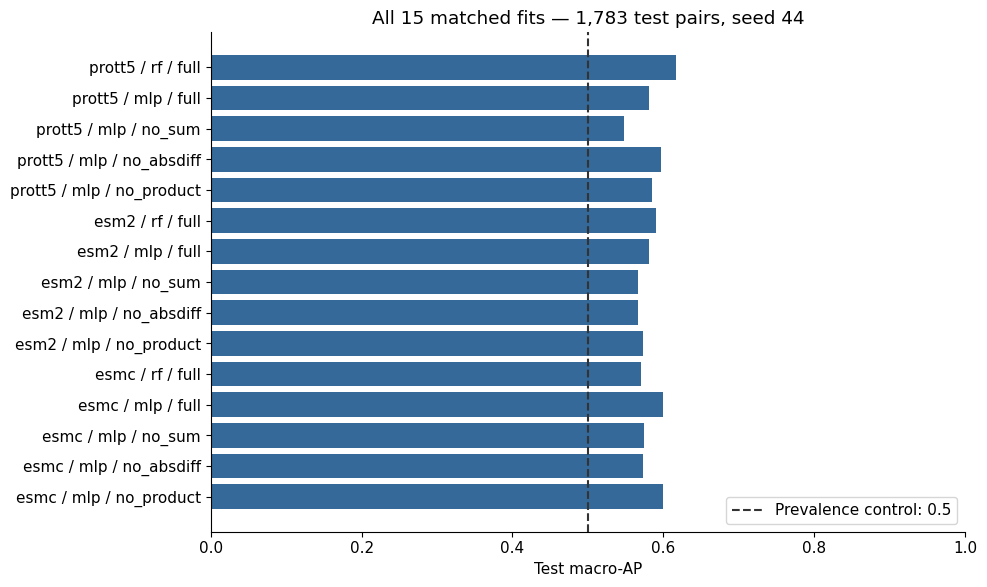

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
labels = test.encoder + " / " + test["head"] + " / " + test.variant
ax.barh(labels, test.macro_ap, color="#34699a")
ax.axvline(0.5, color="#333333", linestyle="--", label="Prevalence control: 0.5")
ax.set(xlim=(0, 1), xlabel="Test macro-AP", title="All 15 matched fits — 1,783 test pairs, seed 44")
ax.invert_yaxis(); ax.legend(loc="lower right"); fig.tight_layout(); plt.show()

## Original training records
The MLP histories record epoch-level training weighted BCE and validation macro-AP. Validation loss, minibatch logs, and optimizer checkpoints were **not saved** in the original run and cannot be reconstructed from these CSVs. RF has no epoch history; its configuration, runtime and final scores are recorded below. No missing logs are fabricated.

In [6]:
display(metrics[(metrics["head"] == "rf") & (metrics["split"] == "test")][["encoder", "seconds", "auroc", "macro_ap", "macro_f1"]].round(4))

,encoder,seconds,auroc,macro_ap,macro_f1
2,prott5,127.2354,0.7279,0.6168,0.5931
17,esm2,132.4692,0.7024,0.5902,0.5554
32,esmc,122.6757,0.6697,0.5706,0.5544


### prott5: four MLP variants
The marked points are the recorded best-validation epochs. Curves are original single-seed histories, not uncertainty intervals.

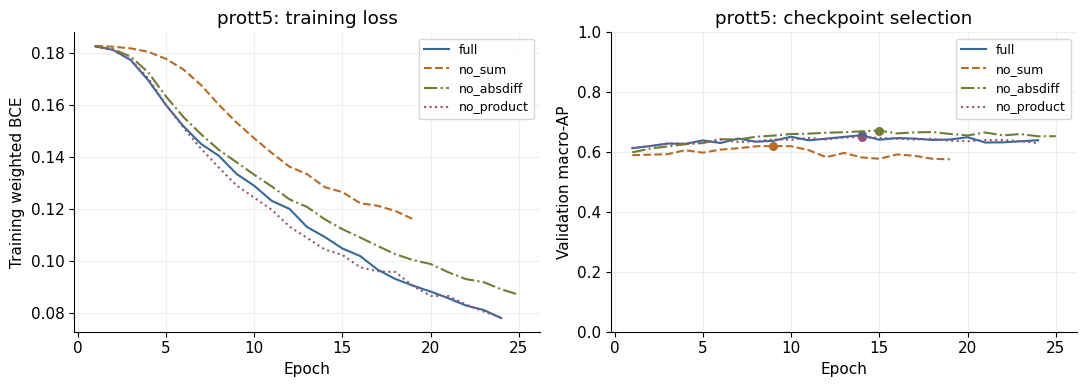

In [7]:
encoder = 'prott5'
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#34699a", "#b86b22", "#737a32", "#99537a"]
styles = ["-", "--", "-.", ":"]
for variant, color, style in zip(["full", "no_sum", "no_absdiff", "no_product"], colors, styles):
    history = pd.read_csv(RESULTS / f"{encoder}_mlp_{variant}_history.csv")
    selected = metrics[(metrics.encoder == encoder) & (metrics["head"] == "mlp") & (metrics.variant == variant) & (metrics["split"] == "test")].iloc[0]
    best = history.loc[history.epoch == int(selected.best_epoch)].iloc[0]
    assert best.epoch == history.loc[history.validation_macro_ap.idxmax(), "epoch"]
    axes[0].plot(history.epoch, history.train_weighted_loss, color=color, linestyle=style, label=variant)
    axes[1].plot(history.epoch, history.validation_macro_ap, color=color, linestyle=style, label=variant)
    axes[1].scatter([best.epoch], [best.validation_macro_ap], color=color, s=30)
axes[0].set(xlabel="Epoch", ylabel="Training weighted BCE", title=f"{encoder}: training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation macro-AP", ylim=(0, 1), title=f"{encoder}: checkpoint selection")
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

#### prott5 / full: complete saved epoch table

In [8]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "prott5_mlp_full_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182717,0.612927
1,2,0.181343,0.619985
2,3,0.177426,0.628449
3,4,0.169585,0.627513
4,5,0.160070,0.639102
5,6,0.151820,0.630268
6,7,0.145004,0.645385
7,8,0.140473,0.634561
8,9,0.133484,0.637812
9,10,0.128921,0.651120


#### prott5 / no_sum: complete saved epoch table

In [9]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "prott5_mlp_no_sum_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182853,0.589827
1,2,0.182562,0.591271
2,3,0.181923,0.593082
3,4,0.180596,0.606332
4,5,0.177877,0.598171
5,6,0.173739,0.608358
6,7,0.167712,0.612894
7,8,0.160152,0.619214
8,9,0.153327,0.620295
9,10,0.147239,0.619549


#### prott5 / no_absdiff: complete saved epoch table

In [10]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "prott5_mlp_no_absdiff_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182707,0.599188
1,2,0.181615,0.611505
2,3,0.178753,0.618932
3,4,0.172649,0.626352
4,5,0.163383,0.630147
5,6,0.155353,0.643103
6,7,0.148709,0.641799
7,8,0.142756,0.651271
8,9,0.138008,0.655017
9,10,0.133178,0.660416


#### prott5 / no_product: complete saved epoch table

In [11]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "prott5_mlp_no_product_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182623,0.613960
1,2,0.181208,0.619874
2,3,0.177579,0.628680
3,4,0.170375,0.628850
4,5,0.160159,0.632080
5,6,0.151270,0.641460
6,7,0.143151,0.633450
7,8,0.135917,0.635887
8,9,0.129058,0.642805
9,10,0.124349,0.641037


### esm2: four MLP variants
The marked points are the recorded best-validation epochs. Curves are original single-seed histories, not uncertainty intervals.

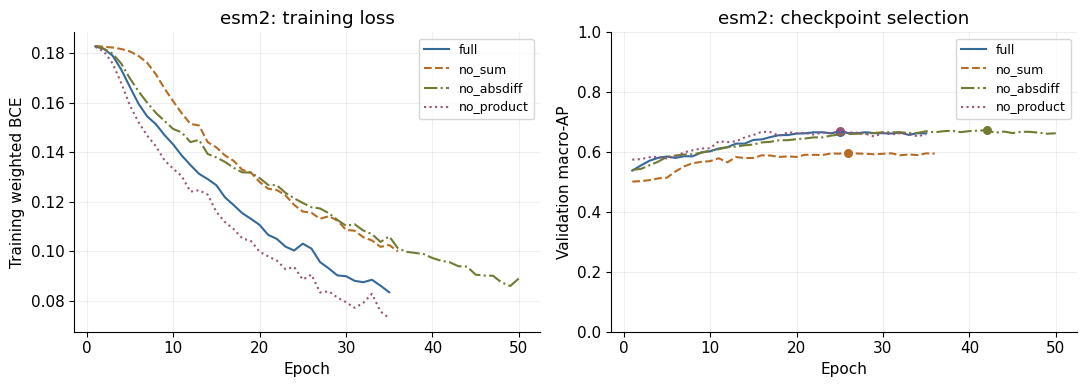

In [12]:
encoder = 'esm2'
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#34699a", "#b86b22", "#737a32", "#99537a"]
styles = ["-", "--", "-.", ":"]
for variant, color, style in zip(["full", "no_sum", "no_absdiff", "no_product"], colors, styles):
    history = pd.read_csv(RESULTS / f"{encoder}_mlp_{variant}_history.csv")
    selected = metrics[(metrics.encoder == encoder) & (metrics["head"] == "mlp") & (metrics.variant == variant) & (metrics["split"] == "test")].iloc[0]
    best = history.loc[history.epoch == int(selected.best_epoch)].iloc[0]
    assert best.epoch == history.loc[history.validation_macro_ap.idxmax(), "epoch"]
    axes[0].plot(history.epoch, history.train_weighted_loss, color=color, linestyle=style, label=variant)
    axes[1].plot(history.epoch, history.validation_macro_ap, color=color, linestyle=style, label=variant)
    axes[1].scatter([best.epoch], [best.validation_macro_ap], color=color, s=30)
axes[0].set(xlabel="Epoch", ylabel="Training weighted BCE", title=f"{encoder}: training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation macro-AP", ylim=(0, 1), title=f"{encoder}: checkpoint selection")
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

#### esm2 / full: complete saved epoch table

In [13]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esm2_mlp_full_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182810,0.538242
1,2,0.181747,0.555247
2,3,0.179044,0.571192
3,4,0.173408,0.580863
4,5,0.166390,0.585097
5,6,0.159594,0.580558
6,7,0.154495,0.586137
7,8,0.151367,0.585976
8,9,0.146957,0.598819
9,10,0.143159,0.602602


#### esm2 / no_sum: complete saved epoch table

In [14]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esm2_mlp_no_sum_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182974,0.501276
1,2,0.182623,0.503109
2,3,0.182335,0.506291
3,4,0.181738,0.512139
4,5,0.180754,0.514300
5,6,0.178934,0.535316
6,7,0.176135,0.552248
7,8,0.171545,0.563090
8,9,0.165793,0.567277
9,10,0.160630,0.569804


#### esm2 / no_absdiff: complete saved epoch table

In [15]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esm2_mlp_no_absdiff_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182841,0.540384
1,2,0.181840,0.543918
2,3,0.179848,0.555915
3,4,0.175828,0.568053
4,5,0.169867,0.584167
5,6,0.164616,0.588344
6,7,0.160042,0.591923
7,8,0.155922,0.592731
8,9,0.152655,0.598194
9,10,0.149418,0.605011


#### esm2 / no_product: complete saved epoch table

In [16]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esm2_mlp_no_product_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182582,0.574828
1,2,0.180692,0.576459
2,3,0.175908,0.582889
3,4,0.167933,0.584257
4,5,0.158906,0.578603
5,6,0.152178,0.585954
6,7,0.146672,0.599151
7,8,0.142471,0.606177
8,9,0.136760,0.611929
9,10,0.133370,0.612733


### esmc: four MLP variants
The marked points are the recorded best-validation epochs. Curves are original single-seed histories, not uncertainty intervals.

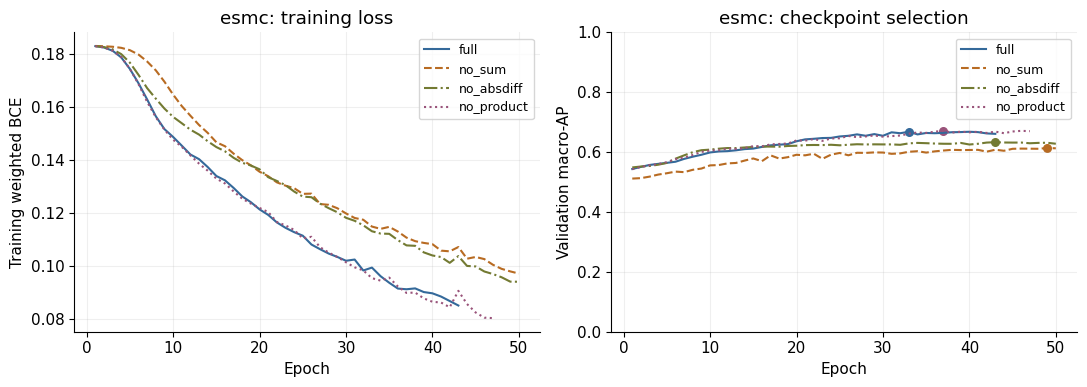

In [17]:
encoder = 'esmc'
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#34699a", "#b86b22", "#737a32", "#99537a"]
styles = ["-", "--", "-.", ":"]
for variant, color, style in zip(["full", "no_sum", "no_absdiff", "no_product"], colors, styles):
    history = pd.read_csv(RESULTS / f"{encoder}_mlp_{variant}_history.csv")
    selected = metrics[(metrics.encoder == encoder) & (metrics["head"] == "mlp") & (metrics.variant == variant) & (metrics["split"] == "test")].iloc[0]
    best = history.loc[history.epoch == int(selected.best_epoch)].iloc[0]
    assert best.epoch == history.loc[history.validation_macro_ap.idxmax(), "epoch"]
    axes[0].plot(history.epoch, history.train_weighted_loss, color=color, linestyle=style, label=variant)
    axes[1].plot(history.epoch, history.validation_macro_ap, color=color, linestyle=style, label=variant)
    axes[1].scatter([best.epoch], [best.validation_macro_ap], color=color, s=30)
axes[0].set(xlabel="Epoch", ylabel="Training weighted BCE", title=f"{encoder}: training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation macro-AP", ylim=(0, 1), title=f"{encoder}: checkpoint selection")
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

#### esmc / full: complete saved epoch table

In [18]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esmc_mlp_full_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182863,0.543561
1,2,0.182359,0.550483
2,3,0.181125,0.557021
3,4,0.178610,0.560652
4,5,0.174240,0.564067
5,6,0.168821,0.567771
6,7,0.162700,0.577272
7,8,0.156362,0.584591
8,9,0.151519,0.591067
9,10,0.148567,0.598805


#### esmc / no_sum: complete saved epoch table

In [19]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esmc_mlp_no_sum_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182940,0.511521
1,2,0.182811,0.512986
2,3,0.182634,0.518019
3,4,0.182226,0.524875
4,5,0.181336,0.529331
5,6,0.179679,0.534795
6,7,0.177046,0.533004
7,8,0.173713,0.540863
8,9,0.169413,0.544999
9,10,0.164568,0.555599


#### esmc / no_absdiff: complete saved epoch table

In [20]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esmc_mlp_no_absdiff_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182893,0.548797
1,2,0.182513,0.551768
2,3,0.181661,0.553682
3,4,0.179848,0.557834
4,5,0.176621,0.563831
5,6,0.171998,0.578007
6,7,0.166980,0.589122
7,8,0.163022,0.599691
8,9,0.159270,0.606295
9,10,0.156151,0.608219


#### esmc / no_product: complete saved epoch table

In [21]:
with pd.option_context("display.max_rows", 60):
    display(pd.read_csv(RESULTS / "esmc_mlp_no_product_history.csv").round(6))

,epoch,train_weighted_loss,validation_macro_ap
0,1,0.182856,0.542644
1,2,0.182348,0.550451
2,3,0.181149,0.556363
3,4,0.178692,0.559868
4,5,0.174298,0.566499
5,6,0.168479,0.576299
6,7,0.161776,0.581666
7,8,0.156015,0.590410
8,9,0.151312,0.600541
9,10,0.147530,0.605283


## Verification and limits
The receipt below is from the original independent verifier, which had access to the private splits and predictions. This public notebook verifies the aggregate source files and training-code identity; it does not repeat the private row-level audit.

Only 46.1% of cleaned pairs were retained. One interaction component contains 68.0% of test pairs. MMseqs2 is heuristic, with a 1,000-candidate cap; legacy ProtT5 lacks preprocessing/revision metadata. See `RESULTS.md` for the full limitations and cloud artifact paths.

In [22]:
display(pd.Series(json.loads((RESULTS / "verification.json").read_text()), name="Original verification").to_frame())

,Original verification
status,passed
source_rows_reconciled,39003
frozen_file_hashes_verified,20
cluster_overlap,0
full_and_both_model_input_overlaps,0
classifier_fits,15
metric_rows,45
test_predictions_verified,26745
mlp_checkpoint_selections_verified,12
